# Task 0: Power as a polynomial of speed and flow (Case 1)

**Owner:** Seb

Use Linear Regression to predict the power **P** from n (in krpm) and Q:

$$P = \sum_{i=0}^{3}\sum_{j=0}^{3} \alpha_{ij}\, n^i Q^j$$

Apply a **feature selection** method to find which terms belong in the formula. Train on train1, test on test1, report the final expression and the test errors, and plot the errors vs flow.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, 
from sklearn.feature_selection import SequentialFeatureSelector
import sympy as sp

import sys
sys.path.append("..")
from src.data import load_case1

In [6]:
df_train, df_test =load_case1()

In [7]:
#we need speed and flow, speed needs to be converted to kr/m

n_train, n_test = df_train["speed_rpm"] / 1000, df_test["speed_rpm"] / 100   #now in kilo-rotations/minute!
Q_train, Q_test = np.array(df_train["flow_m3_h"]), np.array(df_test["flow_m3_h"])
y_train, y_test = np.array(df_train["power_w"]), np.array(df_test["power_w"]) #target variable

In [8]:
#design matrix X will have 16 featuers (cycling through both sum signs)
# X = [1, Q, Q**2, ..., n**3'Q**3]

X_trainlist, X_testlist = [], []
index = 0

for i in range(4):
    for j in range(4):
        X_trainlist.append(n_train**i * Q_train**j)
        X_testlist.append(n_test**i * Q_test**j)

X_train = np.array(X_trainlist).T
X_test = np.array(X_testlist).T


Text(0.5, 1.0, 'Relationship between number of features in model and mean squared error (MSE)')

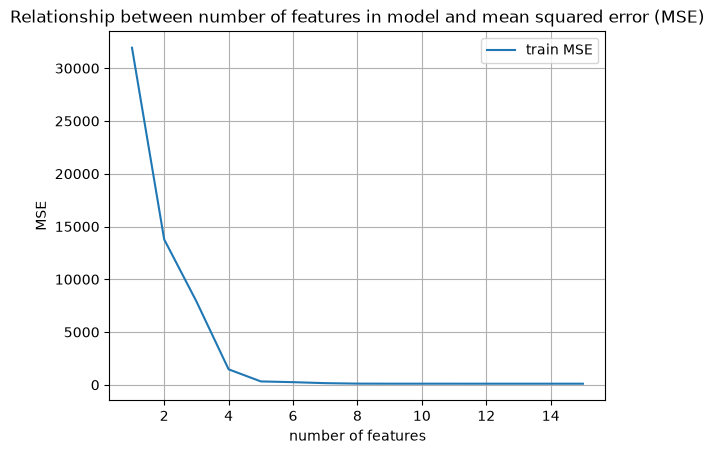

In [34]:
#Testing performance of different models from backward selection

no_fts = np.arange(1,16) #because there are 15 features
model = LinearRegression()
train_mse, test_mse = [],[]
for i in no_fts:
    sfs = SequentialFeatureSelector(model, direction = "backward", cv = 5, n_features_to_select= i)
    sfs.fit(X_train, y_train)
    selected_X_train = sfs.transform(X_train)
    fit = LinearRegression().fit(selected_X_train, y_train)

    #getting train MSE
    train_pred = fit.predict(selected_X_train)
    train_mse.append(mean_squared_error(y_train, train_pred))

    # #getting test MSE
    # selected_X_test = sfs.transform(X_test)
    # test_pred = fit.predict(selected_X_test)
    # test_mse.append(mean_squared_error(y_test, test_pred))

plt.plot(no_fts, train_mse, label = "train MSE")
#plt.plot(no_fts, test_mse, label = "test MSE") #We should not be using the test MSE to find the model!


plt.xlabel("number of features")
plt.ylabel("MSE")
plt.legend()
plt.grid()
plt.title("Relationship between number of features in model and mean squared error (MSE)")

In [13]:
#Hm, it seems like we can choose 4 features if the value is less than 1/2 st dev away from 5 features.

st_dev = np.std(train_mse)
mean = np.mean(train_mse)

stds = abs(train_mse[4]-train_mse[3])/st_dev #We can choose 4 features!
print("number of standard deveations between 4 and 5 features models: ", stds)

number of standard deveations between 4 and 5 features models:  0.13633718212840573


In [33]:
sfs = SequentialFeatureSelector(model, direction = "backward", cv = 5, n_features_to_select= 4)
sfs.fit(X_train, y_train)

X_train_selected = sfs.transform(X_train)
X_test_selected = sfs.transform(X_test)
best_model = LinearRegression().fit(X_train_selected, y_train)

n , Q = sp.symbols("n, Q")

design_matrix = []

for i in range(4):
    for j in range(4):
        design_matrix.append(n**i * Q**j)

print("Selected features: ")
for i in np.argwhere(sfs.get_support() ==True).flatten():
    print (design_matrix[i])
print("\n")
print("Coefficients: ", best_model.coef_)


Selected features: 
Q*n
Q**2*n
Q**2*n**2
n**3


Coefficients:  [12.36186374 -0.48277995  0.06948715  8.91915894]


In [ ]:
y_pred = best_model.predict(X_test_selected)
print("Test mean squared error for selected model: ", mean_squared_error(y_test, y_pred))

Test mean squared error for selected model:  270180528216.3349
